In [50]:
import tensorflow as tf
from keras.datasets import mnist
from keras import layers
from keras.models import Sequential
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np


In [34]:
(X_train,y_train),(X_test,y_test) = mnist.load_data()



In [35]:
X_train = X_train.reshape((X_train.shape[0],28,28,1)).astype('float32')/255
X_test =  X_test.reshape((X_test.shape[0],28,28,1)).astype('float32')/255


y_train = tf.keras.utils.to_categorical(y_train)
y_test = tf.keras.utils.to_categorical(y_test)

In [36]:
X_train.shape

(60000, 28, 28, 1)

In [37]:
X_train.shape

(60000, 28, 28, 1)

In [38]:
X_test.shape

(10000, 28, 28, 1)

In [39]:
model = Sequential()

model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(layers.MaxPooling2D((2, 2)))


model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))


model.add(layers.Conv2D(64, (3, 3), activation='relu'))


model.add(layers.Flatten())


model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))

In [40]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [41]:
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_data=(X_test, y_test))

Epoch 1/5
938/938 [==============================] - 21s 21ms/step - loss: 0.1838 - accuracy: 0.9437 - val_loss: 0.0479 - val_accuracy: 0.9845
Epoch 2/5
938/938 [==============================] - 21s 22ms/step - loss: 0.0491 - accuracy: 0.9850 - val_loss: 0.0394 - val_accuracy: 0.9877
Epoch 3/5
938/938 [==============================] - 23s 24ms/step - loss: 0.0361 - accuracy: 0.9894 - val_loss: 0.0288 - val_accuracy: 0.9895
Epoch 4/5
938/938 [==============================] - 22s 23ms/step - loss: 0.0304 - accuracy: 0.9904 - val_loss: 0.0330 - val_accuracy: 0.9888
Epoch 5/5
938/938 [==============================] - 21s 22ms/step - loss: 0.0233 - accuracy: 0.9927 - val_loss: 0.0301 - val_accuracy: 0.9904


In [42]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc}")

313/313 [==============================] - 1s 4ms/step - loss: 0.0301 - accuracy: 0.9904
Test accuracy: 0.9904000163078308


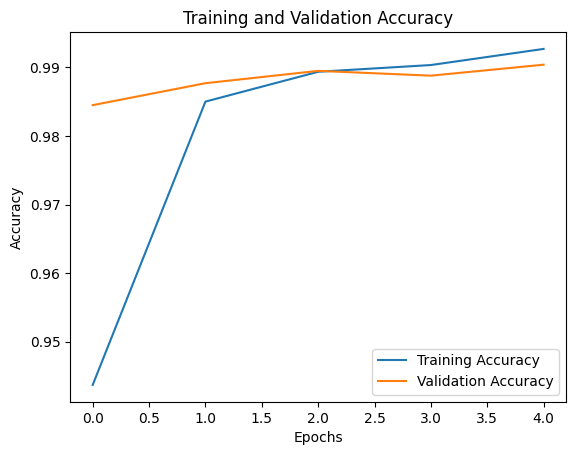

In [45]:
# Plotting the training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Predicted class: 1
True class: 1


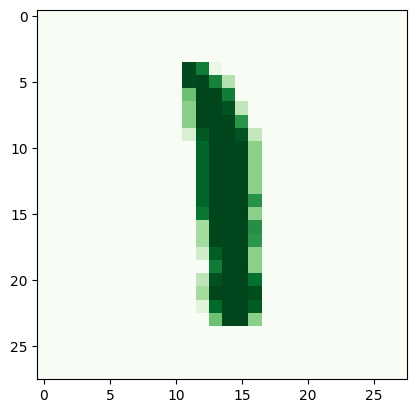

In [57]:
# Predicting the class for test images
predictions = model.predict(X_test)

plt.imshow(X_test[777].reshape(28,28),cmap='Greens')

# Print the predicted class for the first test image
print(f"Predicted class: {predictions[777].argmax()}")
print(f"True class: {y_test[777].argmax()}")